# Task 1.3: Convolution and Deconvolution

**Student Name:** Haris Salii  
**Country:** Switzerland  
**Semester term:** HS26


## Day 11 Data & Domain

### Use Case

Für die kurzfristige Betriebsplanung einer Photovoltaikanlage im Raum Bern soll ein geglätteter Verlauf der Globalstrahlung den allgemeinen Einstrahlungstrend sichtbar machen. Betreiber können diesen Verlauf für Batterie- und Einspeiseentscheidungen nutzen. Der Anwendungsfall ist für die Schweiz relevant, weil der wachsende Solarstromanteil wetterabhängige und kurzfristig schwankende Einspeisung erzeugt.

### Problem Statement

Die 10-Minuten-Werte enthalten starke aufeinanderfolgende Änderungen, welche den allgemeinen Verlauf überdecken können. Eine Faltung mit einem zu breiten Glättungskern kann jedoch relevante Einbrüche und Spitzen abschwächen. Die Entfaltung soll deshalb untersuchen, wie weit sich die ursprüngliche Struktur aus dem geglätteten Signal rekonstruieren lässt und wann dabei Störungen verstärkt werden.

### Experimental Objective

Untersucht wird der Zielkonflikt zwischen einem ruhigeren Verlauf und dem Erhalt kurzfristiger Strahlungsänderungen. Für die PV-Planung ist entscheidend, ob eine stabile Rekonstruktion die durch die Glättung abgeschwächte Struktur wieder annähert.

### Data Definition and Source

Verwendet wird die Globalstrahlung `gre000z0` der MeteoSwiss-Station Bern/Zollikofen (`BER`) in **W/m²**. Die Werte sind gleichmässig erfasste **10-Minuten-Mittelwerte** aus dem Datensatz *Automatic Weather Stations Measurement Values*. Das einzige Untersuchungsfenster umfasst den **21. Juli 2025 von 09:00 bis 15:00 Uhr** und enthält 37 aufeinanderfolgende Werte ohne fehlende oder doppelte Zeitstempel. Der Abschnitt ist geeignet, weil er einen Tagestrend und mehrere kurze Einbrüche und Erholungen im selben Signal zeigt.

Quelle: MeteoSwiss, Automatic Weather Stations Measurement Values, Station `BER`, Parameter `gre000z0`: https://opendatadocs.meteoswiss.ch/de/a-data-groundbased/a1-automatic-weather-stations

Anzahl Werte: 37
Fehlende Strahlungswerte: 0
Doppelte Zeitstempel: 0


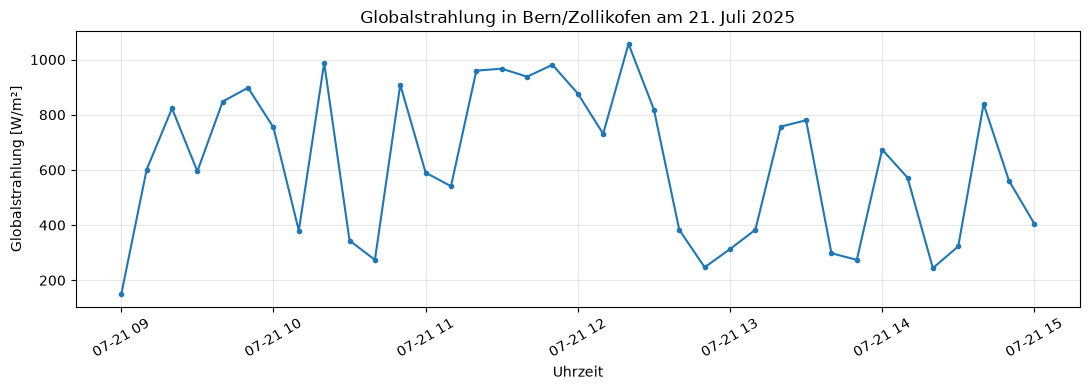

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("../data/solarstrahlung_bern_2025.csv", sep=";")
data["time"] = pd.to_datetime(data["reference_timestamp"], dayfirst=True)

window = data[
    (data["time"] >= "2025-07-21 09:00")
    & (data["time"] <= "2025-07-21 15:00")
].copy()

print("Anzahl Werte:", len(window))
print("Fehlende Strahlungswerte:", window["gre000z0"].isna().sum())
print("Doppelte Zeitstempel:", window["time"].duplicated().sum())

plt.figure(figsize=(11, 4))
plt.plot(window["time"], window["gre000z0"], marker="o", markersize=3)
plt.xlabel("Uhrzeit")
plt.ylabel("Globalstrahlung [W/m²]")
plt.title("Globalstrahlung in Bern/Zollikofen am 21. Juli 2025")
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation

Zwischen 09:00 und 15:00 Uhr ist kein gleichmässiger Verlauf sichtbar. Auf starke Anstiege folgen mehrere deutliche Einbrüche, besonders im Bereich um 10:00–11:00 Uhr und nach 12:20 Uhr. Damit enthält das Fenster genau die kurzfristige Struktur, deren Abschwächung durch die Faltung und deren teilweise Wiederherstellung durch die Entfaltung untersucht werden soll. Die Messwerte sind bereits über zehn Minuten gemittelt; schnellere Änderungen innerhalb eines Intervalls sind nicht enthalten.

## Day 12 Methodological Design

### Theoretical Foundation and Method Choice

Die diskrete Faltung berechnet jeden Ausgabewert als gewichtete Summe benachbarter Signalwerte:

$$y[n] = \sum_k h[k]\,x[n-k].$$

Ein symmetrischer gleitender Mittelwert ist passend, weil er schnelle Änderungen dämpft, die Summe seiner Gewichte aber 1 beträgt und das mittlere Strahlungsniveau dadurch erhalten bleibt. Verglichen werden ein 3-Punkte-Kern $h_3=[1/3,1/3,1/3]$ und ein 5-Punkte-Kern $h_5=[1/5,\ldots,1/5]$. Der erste glättet über 30 Minuten, der zweite über 50 Minuten.

Für die Entfaltung wurden drei Ansätze betrachtet. Eine direkte Inversion kann bei einem störungsfreien, exakt bekannten Filter gute Resultate liefern, reagiert aber empfindlich auf kleine Störungen. Ein Wiener-Filter berücksichtigt ein Signal- und Rauschmodell, für dieses einzelne Tagesfenster liegt jedoch kein verlässliches Leistungsspektrum des Rauschens vor. Gewählt wird deshalb eine **Tikhonov-regularisierte Inversion**, weil ihre Stabilisierung über einen sichtbaren Parameter $\lambda$ gesteuert werden kann:

$$\hat{x}=(H^T H+\lambda I)^{-1}H^T y.$$

Dabei beschreibt $H$ die Faltung als Matrix. Grössere Werte von $\lambda$ begrenzen die Verstärkung von Störungen stärker, erzeugen aber mehr Abweichung vom Original.

### Parameters and Performance Requirement

Die Abtastzeit beträgt 10 Minuten. Als Baseline dienen der 3-Punkte-Kern, Randfortsetzung mit dem jeweils äussersten Messwert und $\lambda=0{,}01$. Der Randmodus erhält die Signallänge von 37 Werten, kann die ersten und letzten Werte aber beeinflussen. Für eine faire Stabilitätsprüfung wird bei allen Konfigurationen dieselbe reproduzierbare additive Störung mit $\sigma=20\,\mathrm{W/m^2}$ verwendet. Sie entspricht ungefähr zwei Prozent der sichtbaren Tagesskala und ist ein kontrollierter Robustheitstest, kein Modell des tatsächlichen MeteoSwiss-Messfehlers.

Die Rekonstruktion gilt für diesen Versuch als praktisch hilfreich, wenn ihr RMSE gegenüber dem Original kleiner ist als der RMSE des geglätteten Signals und keine deutlich unplausiblen Ausschläge entstehen. Diese Aussage bezieht sich nur auf die Wiederherstellung der hier bekannten 10-Minuten-Werte.

### Experimental Design

Die Kernelgrösse wird systematisch zwischen 3 und 5 Punkten variiert. Für die Regularisierung werden $\lambda\in\{0;0{,}001;0{,}01;0{,}1\}$ verglichen; $\lambda=0$ entspricht der direkten Inversion. Das Zeitfenster, die Randbehandlung und die Störung bleiben konstant. Erwartet wird, dass der 5-Punkte-Kern stärker glättet und dass eine mittlere Regularisierung bei gestörten Daten stabiler rekonstruiert als die direkte Inversion.

### Methodological Limitations

Das Verfahren nimmt einen linearen, exakt bekannten Filter an. In realen Messketten können unbekannte Störungen, andere Filter und nichtlineare Effekte diese Annahme verletzen. Ausserdem kann keine Entfaltung Änderungen wiederherstellen, die bereits durch die ursprüngliche 10-Minuten-Mittelung verloren gingen.


## Day 13 Implementation


### Manual convolution

Die folgende Funktion setzt die Faltung selbst um: Das Signal wird am Rand fortgesetzt, der umgedrehte Kernel wird über das Signal geschoben und pro Position wird die Summe der Produkte gebildet. `np.convolve` wird anschliessend ausschliesslich zur Kontrolle verwendet.

In [2]:
signal = window["gre000z0"].to_numpy(dtype=float)
times = window["time"].reset_index(drop=True)

kernel_3 = np.ones(3) / 3
kernel_5 = np.ones(5) / 5


def manual_convolution(values, kernel):
    padding = len(kernel) // 2
    padded_values = np.pad(values, padding, mode="edge")
    flipped_kernel = kernel[::-1]
    result = np.zeros(len(values), dtype=float)

    for position in range(len(values)):
        local_values = padded_values[position:position + len(kernel)]
        result[position] = np.sum(local_values * flipped_kernel)

    return result


filtered_3 = manual_convolution(signal, kernel_3)
library_result = np.convolve(
    np.pad(signal, 1, mode="edge"),
    kernel_3,
    mode="valid",
)

maximum_difference = np.max(np.abs(filtered_3 - library_result))
print(f"Maximale Abweichung zur NumPy-Kontrolle: {maximum_difference:.12f} W/m²")


Maximale Abweichung zur NumPy-Kontrolle: 0.000000000000 W/m²


Die maximale Abweichung von **0 W/m²** bestätigt, dass die manuelle Faltung und die NumPy-Kontrolle für den Baseline-Kern übereinstimmen.

### Regularized deconvolution

Die Faltungsmatrix wird mit derselben manuellen Funktion aufgebaut. Dadurch verwenden Faltung und Entfaltung dieselbe Randbehandlung. Bei $\lambda=0$ wird eine direkte Kleinste-Quadrate-Lösung berechnet; positive Werte verwenden die geplante Tikhonov-Regularisierung.

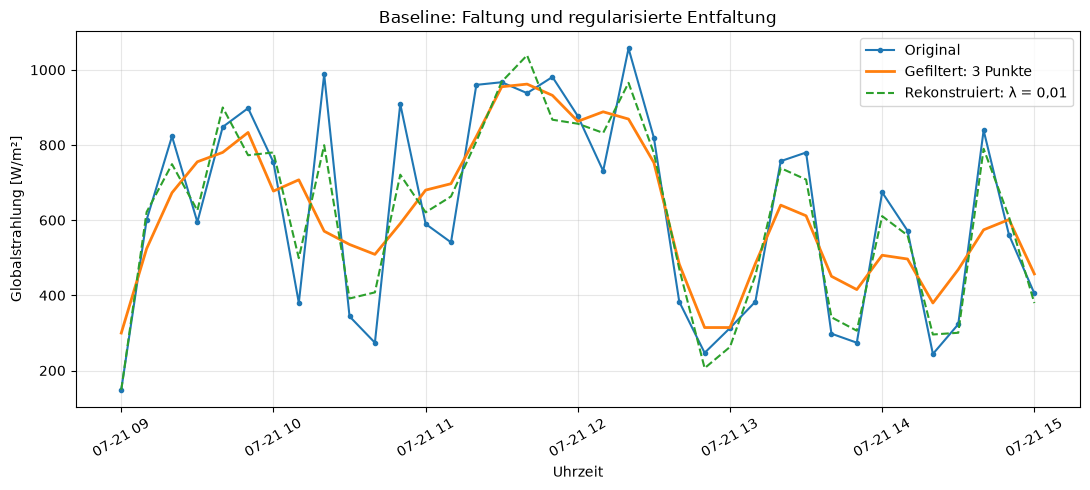

In [3]:
def convolution_matrix(signal_length, kernel):
    matrix = np.zeros((signal_length, signal_length))

    for column in range(signal_length):
        basis_vector = np.zeros(signal_length)
        basis_vector[column] = 1.0
        matrix[:, column] = manual_convolution(basis_vector, kernel)

    return matrix


def deconvolve(filtered_values, kernel, regularization):
    matrix = convolution_matrix(len(filtered_values), kernel)

    if regularization == 0:
        return np.linalg.lstsq(matrix, filtered_values, rcond=None)[0]

    left_side = matrix.T @ matrix + regularization * np.eye(len(filtered_values))
    right_side = matrix.T @ filtered_values
    return np.linalg.solve(left_side, right_side)


baseline_regularization = 0.01
reconstructed_3 = deconvolve(
    filtered_3,
    kernel_3,
    baseline_regularization,
)

plt.figure(figsize=(11, 5))
plt.plot(times, signal, marker="o", markersize=3, label="Original")
plt.plot(times, filtered_3, linewidth=2, label="Gefiltert: 3 Punkte")
plt.plot(times, reconstructed_3, linestyle="--", label="Rekonstruiert: λ = 0,01")
plt.xlabel("Uhrzeit")
plt.ylabel("Globalstrahlung [W/m²]")
plt.title("Baseline: Faltung und regularisierte Entfaltung")
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## Day 14 Evaluation

### Evaluation Approach Definition

Als einheitliche Kennzahl wird der **Root Mean Squared Error (RMSE)** gegenüber dem Originalsignal verwendet:

$$RMSE=\sqrt{\frac{1}{N}\sum_{n=1}^{N}(x[n]-\hat{x}[n])^2}.$$

Der RMSE eignet sich hier, weil er die durchschnittliche Amplitudenabweichung in derselben Einheit wie die Globalstrahlung, **W/m²**, ausdrückt und grössere Abweichungen stärker gewichtet. Für jede Konfiguration wird er gleichermassen auf das geglättete Signal, die saubere Rekonstruktion und die Rekonstruktion aus dem gestörten Filtersignal angewendet. Das gemessene Original ist innerhalb dieses konstruierten Experiments die Referenz, aber keine hochaufgelöste Wahrheit über Änderungen innerhalb der 10-Minuten-Intervalle.

In [4]:
def rmse(reference, estimate):
    return np.sqrt(np.mean((reference - estimate) ** 2))


random_generator = np.random.default_rng(42)
fixed_noise = random_generator.normal(0, 20, len(signal))

kernels = {
    "3 Punkte": kernel_3,
    "5 Punkte": kernel_5,
}
regularization_values = [0, 0.001, 0.01, 0.1]
evaluation_rows = []

for kernel_name, kernel in kernels.items():
    filtered = manual_convolution(signal, kernel)
    noisy_filtered = filtered + fixed_noise
    filtered_error = rmse(signal, filtered)

    for regularization in regularization_values:
        clean_reconstruction = deconvolve(filtered, kernel, regularization)
        noisy_reconstruction = deconvolve(
            noisy_filtered,
            kernel,
            regularization,
        )
        noisy_error = rmse(signal, noisy_reconstruction)

        evaluation_rows.append({
            "Kernel": kernel_name,
            "Breite [min]": len(kernel) * 10,
            "λ": regularization,
            "Filter-RMSE [W/m²]": filtered_error,
            "Rekonstruktion sauber RMSE [W/m²]": rmse(
                signal,
                clean_reconstruction,
            ),
            "Rekonstruktion gestört RMSE [W/m²]": noisy_error,
            "Verbesserung ggü. Filterung [%]": (
                (filtered_error - noisy_error) / filtered_error * 100
            ),
        })

evaluation_table = pd.DataFrame(evaluation_rows)
display(evaluation_table.round(2))

best_index = evaluation_table[
    "Rekonstruktion gestört RMSE [W/m²]"
].idxmin()
best_result = evaluation_table.loc[best_index]

print("Beste Konfiguration bei Störung:")
print("Kernel:", best_result["Kernel"])
print("λ:", best_result["λ"])
print(
    "RMSE:",
    f'{best_result["Rekonstruktion gestört RMSE [W/m²]"]:.2f} W/m²',
)


,Kernel,Breite [min],λ,Filter-RMSE [W/m²],Rekonstruktion sauber RMSE [W/m²],Rekonstruktion gestört RMSE [W/m²],Verbesserung ggü. Filterung [%]
0,3 Punkte,30,0.00,159.61,0.00,102.94,35.50
1,3 Punkte,30,0.00,159.61,42.60,102.38,35.86
2,3 Punkte,30,0.01,159.61,82.40,112.50,29.51
3,3 Punkte,30,0.10,159.61,145.12,149.49,6.34
4,5 Punkte,50,0.00,217.44,0.00,236.53,-8.78
5,5 Punkte,50,0.00,217.44,44.71,117.81,45.82
6,5 Punkte,50,0.01,217.44,87.99,115.50,46.88
7,5 Punkte,50,0.10,217.44,164.99,166.11,23.61


Beste Konfiguration bei Störung:
Kernel: 3 Punkte
λ: 0.001
RMSE: 102.38 W/m²


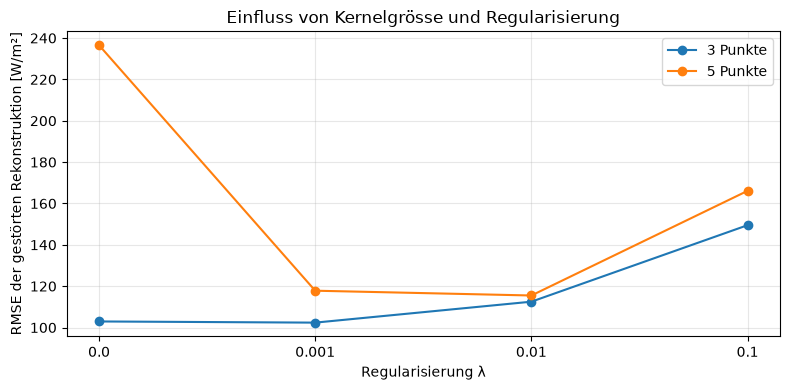

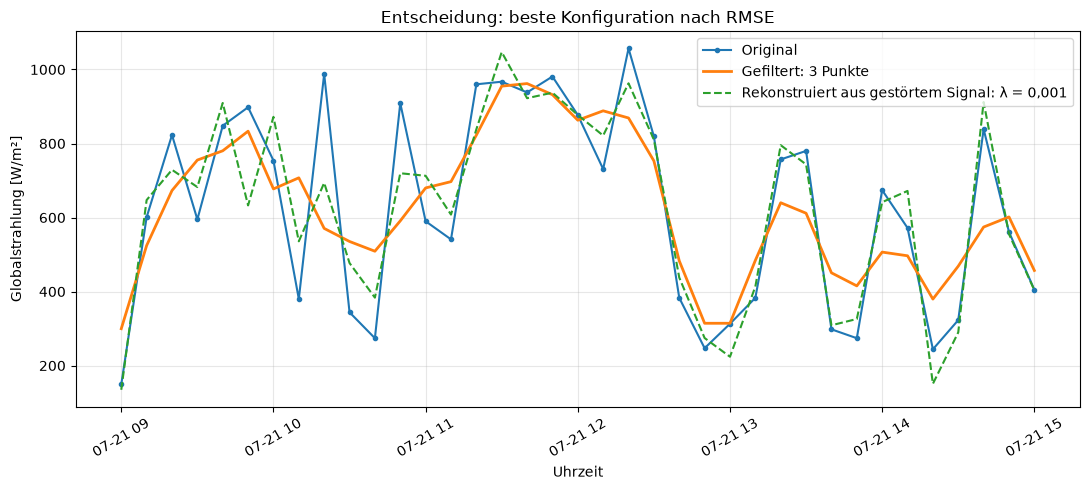

In [5]:
plt.figure(figsize=(8, 4))

for kernel_name in kernels:
    kernel_rows = evaluation_table[evaluation_table["Kernel"] == kernel_name]
    plt.plot(
        kernel_rows["λ"].astype(str),
        kernel_rows["Rekonstruktion gestört RMSE [W/m²]"],
        marker="o",
        label=kernel_name,
    )

plt.xlabel("Regularisierung λ")
plt.ylabel("RMSE der gestörten Rekonstruktion [W/m²]")
plt.title("Einfluss von Kernelgrösse und Regularisierung")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

best_kernel = kernel_3
best_lambda = 0.001
best_filtered = manual_convolution(signal, best_kernel)
best_noisy_reconstruction = deconvolve(
    best_filtered + fixed_noise,
    best_kernel,
    best_lambda,
)

plt.figure(figsize=(11, 5))
plt.plot(times, signal, marker="o", markersize=3, label="Original")
plt.plot(times, best_filtered, linewidth=2, label="Gefiltert: 3 Punkte")
plt.plot(
    times,
    best_noisy_reconstruction,
    linestyle="--",
    label="Rekonstruiert aus gestörtem Signal: λ = 0,001",
)
plt.xlabel("Uhrzeit")
plt.ylabel("Globalstrahlung [W/m²]")
plt.title("Entscheidung: beste Konfiguration nach RMSE")
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### Quantitative Decision

Nach dem vorab definierten RMSE-Kriterium ist der **3-Punkte-Kern mit $\lambda=0{,}001$** die beste untersuchte Konfiguration für die gestörte Rekonstruktion. Die Tabelle dient als direkter Vergleich zur Baseline aus 3 Punkten und $\lambda=0{,}01$; die fachliche Erklärung und Einordnung folgt an Day 15.

## Day 15 Analysis & Communication